# Combined Footing
**ACI 318-19 · ASCE 7-22 (ASD for soil, LRFD for concrete) · IBC 2024**

Rectangular footing supporting two columns along its length. Checks linear soil bearing
pressure with partial contact (no tension), longitudinal shear and moment diagrams from
net factored soil pressure, bottom and top longitudinal steel, one-way shear, punching shear
at each column (3-sided at footing ends), transverse strip steel under each column, minimum
steel, bar spacing, and column bearing.

**How to use:** Run the **Engine** cell once, edit the form fields below, and run **Runtime → Run all** (`Ctrl+F9` / `⌘F9`).

> Design aid only. A licensed engineer must verify all inputs and results.

In [1]:
#@title Engine — run this cell first (embedded structcalc library) { display-mode: "form" }
# Unpacks the embedded structcalc library and imports it (no pip install or Drive mount needed).
# Source: structural-calculations (lib/structcalc). Rebuild notebooks with: python build.py
import base64 as _b64, io as _io, os as _os, sys as _sys, tempfile as _tf, zipfile as _zf
_ZIP = (
    "..."
)
_dir = _os.path.join(_tf.gettempdir(), "structcalc_644fa72374")
if not _os.path.isdir(_os.path.join(_dir, "structcalc")):
    _zf.ZipFile(_io.BytesIO(_b64.b64decode(_ZIP))).extractall(_dir)
for _m in [m for m in _sys.modules if m == "structcalc" or m.startswith("structcalc.")]:
    del _sys.modules[_m]
if _dir not in _sys.path:
    _sys.path.insert(0, _dir)
import structcalc
print(f"structcalc {structcalc.__version__} ready (build 644fa72374)")

structcalc 0.1.0 ready (build 644fa72374)


In [2]:
#@title 1. Footing geometry and materials
length = 20.0  #@param {type:"number"}
width = 8.0  #@param {type:"number"}
thickness = 36.0  #@param {type:"number"}
soil_cover = 1.0  #@param {type:"number"}
fc = 3000.0  #@param {type:"number"}
fy = 60000.0  #@param {type:"number"}
gamma_concrete = 150.0  #@param {type:"number"}
gamma_soil = 110.0  #@param {type:"number"}
#@markdown Length, width, soil cover in **ft**; thickness in **in**; f'c, fy in **psi**; unit weights in **pcf**.

In [3]:
#@title 2. Columns (x = center distance from the left end of the footing)
col1_x = 1.5  #@param {type:"number"}
col1_size_x = 16.0  #@param {type:"number"}
col1_size_y = 16.0  #@param {type:"number"}
col2_x = 16.0  #@param {type:"number"}
col2_size_x = 18.0  #@param {type:"number"}
col2_size_y = 18.0  #@param {type:"number"}
#@markdown x in **ft**; column sizes in **in** (size_x is along the footing length).

In [4]:
#@title 3. Reinforcement
bar_bottom = 7  #@param [4, 5, 6, 7, 8, 9, 10, 11] {type:"raw"}
spacing_bottom = 8.0  #@param {type:"number"}
bar_top = 8  #@param [4, 5, 6, 7, 8, 9, 10, 11] {type:"raw"}
spacing_top = 6.0  #@param {type:"number"}
bar_transverse = 6  #@param [4, 5, 6, 7, 8, 9, 10, 11] {type:"raw"}
spacing_transverse = 6.0  #@param {type:"number"}
bottom_cover = 3.0  #@param {type:"number"}
top_cover = 2.0  #@param {type:"number"}
strip_extension = 0.75  #@param {type:"number"}
#@markdown Spacings and covers in **in**. Transverse bars are the lowest layer. Each transverse strip extends *strip_extension* × d beyond each column face.

In [5]:
#@title 4. Soil and surcharge
allowable_pressure = 3.0  #@param {type:"number"}
increase_for_wind_seismic = 1.0  #@param {type:"number"}
surcharge_D = 0.0  #@param {type:"number"}
surcharge_L = 0.0  #@param {type:"number"}
#@markdown Allowable pressure in **ksf** (gross). Surcharges in **psf** over the full footing area.

In [6]:
#@title 5. Service column loads
#@markdown Each case: `P, M` in **kip** and **kip-ft** (P + down, M + clockwise = moves the soil resultant toward the right end).
col1_D = "80, 0"  #@param {type:"string"}
col1_L = "50, 0"  #@param {type:"string"}
col1_Lr = ""  #@param {type:"string"}
col1_S = ""  #@param {type:"string"}
col1_W = ""  #@param {type:"string"}
col1_E = ""  #@param {type:"string"}
col2_D = "120, 0"  #@param {type:"string"}
col2_L = "80, 0"  #@param {type:"string"}
col2_Lr = ""  #@param {type:"string"}
col2_S = ""  #@param {type:"string"}
col2_W = "0, 60"  #@param {type:"string"}
col2_E = ""  #@param {type:"string"}

In [7]:
#@title 6. Calculate
from structcalc.calcs import combined_footing

def _loads(d):
    return {c: combined_footing.parse_pm(s) for c, s in d.items() if s.strip()}

out = combined_footing.run(
    L=length, B=width, h=thickness, x1=col1_x, c1x=col1_size_x, c1y=col1_size_y,
    x2=col2_x, c2x=col2_size_x, c2y=col2_size_y, soil_cover=soil_cover,
    gamma_c=gamma_concrete, gamma_s=gamma_soil, sur_D=surcharge_D, sur_L=surcharge_L,
    qa=allowable_pressure, qa_increase_WE=increase_for_wind_seismic, fc=fc, fy=fy,
    bar_bot=bar_bottom, s_bot=spacing_bottom, bar_top=bar_top, s_top=spacing_top,
    bar_tr=bar_transverse, s_tr=spacing_transverse, cover=bottom_cover, top_cover=top_cover,
    strip_ext=strip_extension,
    col1=_loads({"D": col1_D, "L": col1_L, "Lr": col1_Lr, "S": col1_S, "W": col1_W, "E": col1_E}),
    col2=_loads({"D": col2_D, "L": col2_L, "Lr": col2_Lr, "S": col2_S, "W": col2_W, "E": col2_E}),
)
out["report"].show()

Footing L x B x h,20 ft x 8 ft x 36 in,
Column 1,"x = 1.5 ft, 16 x 16 in",
Column 2,"x = 16 ft, 18 x 18 in",
Soil cover / unit weights,"1 ft / 150, 110 pcf",
Surcharge D / L,0 / 0,psf
Allowable soil pressure,3,ksf
f'c / fy,3000 / 60000,psi
Longitudinal bottom / top,#7 @ 8 / #8 @ 6 in,
"Transverse (bottom, lowest layer)",#6 @ 6 in,
"Load D: col 1 (P, M) / col 2 (P, M)","80, 0 / 120, 0","kip, kip-ft"
"Load L: col 1 (P, M) / col 2 (P, M)","50, 0 / 80, 0","kip, kip-ft"


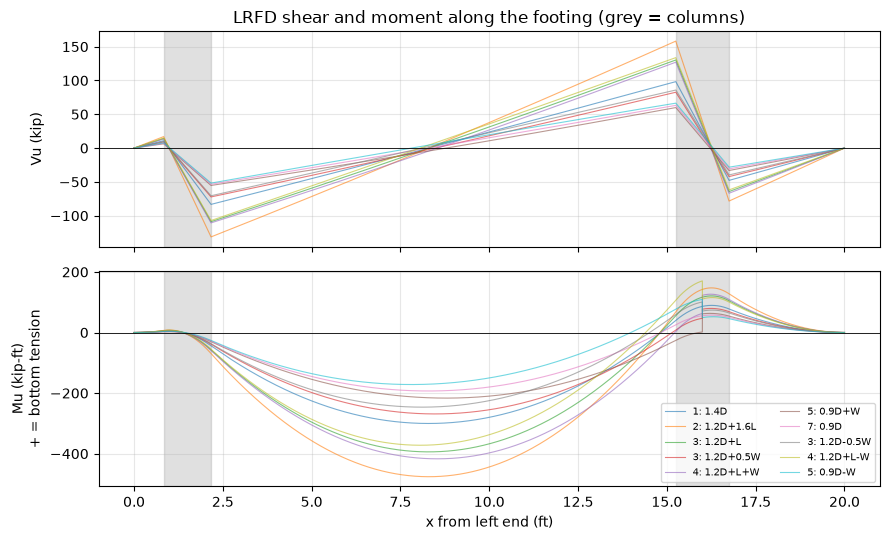

In [8]:
#@title 7. Shear and moment diagrams (all LRFD combinations)
fig = combined_footing.plot(out)

In [9]:
#@title 8. Save report as HTML (optional)
save_report = False  #@param {type:"boolean"}
if save_report:
    path = out["report"].save_html("combined_footing.html")
    print("saved", path)
    try:
        from google.colab import files
        files.download(path)
    except ImportError:
        pass